# Part B: Flow Matching from Scratch
CS180 Project 3 · MNIST denoising and flow matching

Based on the supplied template and [official Part B instructions](https://cal-cs180.github.io/fa26/hw/proj3-flow/partb.html).

**Conventions:** pixels are in [0,1]; flow time runs from noise at t=0 to data at t=1. The network predicts velocity x1−x0. Part B classifier-free guidance is vu + 5(vc−vu).

Run all cells on a fresh GPU runtime. Each experiment trains independently on all 60,000 training images. Test digits are reserved for visualization. Checkpoints are saved after every epoch; figures and raw losses are exported at the end. Results and interpretations should be reviewed after execution.


## Completed run record
All five experiments completed on a Tesla T4. The outputs below contain the actual exported figures and measured epoch summaries. An earlier hosted runtime expired; its denoising and time-only figures and summaries were recovered from notebook outputs. Execution counts are intentionally unset because the experiments completed across two runtimes. Raw step losses and model weights from the earlier runtime were unavailable; class-conditioned step losses and checkpoints were preserved. Rerun all code on a fresh GPU to reproduce the complete experiment sequence.


## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [ ]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

## Setup environment

In [ ]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [ ]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partB')
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))
from contextlib import nullcontext
import gc, zipfile, shutil
CKPT = Path('checkpoints/partB'); CKPT.mkdir(parents=True, exist_ok=True)
USE_AMP = device.type == 'cuda'
metrics['precision'] = 'CUDA mixed precision (float16 convolutions, float32 loss)' if USE_AMP else 'float32'

def amp_context():
    return torch.autocast(device_type='cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if device.type == 'cuda': torch.cuda.manual_seed_all(seed)

def save_metrics():
    (OUT/'metrics.json').write_text(json.dumps(metrics, indent=2))

def release_gpu():
    gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()

# Test examples never enter the optimizer. Reuse these noise draws across epochs.
test_images = test_dataset.data[:10, None].float().to(device)/255
sample_generator = torch.Generator(device=device).manual_seed(SEED+1)
test_epsilon = torch.randn(test_images.shape, generator=sample_generator, device=device)
SIGMAS = [0., .2, .4, .5, .6, .8, 1.]

@torch.inference_mode()
def denoising_panel(net, epoch, prefix='1_2_1'):
    net.eval()
    z = test_images + .5*test_epsilon
    pred = net(z)
    show_grid(torch.cat((test_images, z, pred)),
              f'Epoch {epoch}: clean / noisy (sigma=0.5) / denoised',
              f'{prefix}_epoch{epoch}.png')
    return F.mse_loss(pred.float(), test_images).item()

def train_epochs(net, name, loader, epochs, lr, objective, callback, decay=False):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=.1**(1/epochs)) if decay else None
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    history, summaries = [], []
    for epoch in range(1, epochs+1):
        started = time.time(); net.train(); total = count = 0
        for step, (x, labels) in enumerate(loader):
            x, labels = x.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_context(): loss = objective(net, x, labels)
            if not torch.isfinite(loss): raise RuntimeError(f'{name}: nonfinite loss at epoch {epoch}, step {step}')
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            value = loss.detach().float().item(); history.append(value)
            total += value*len(x); count += len(x)
            if step % 200 == 0: print(f'{name} epoch {epoch}/{epochs}, batch {step}/{len(loader)}, loss {value:.5f}', flush=True)
        row = {'epoch':epoch, 'mse':total/count, 'lr':optimizer.param_groups[0]['lr'], 'seconds':time.time()-started}
        summaries.append(row)
        print(name, row, flush=True)
        if scheduler: scheduler.step()
        # Save every epoch before producing plots. Intermediate results survive a failed later cell.
        torch.save({'model':net.state_dict(),'optimizer':optimizer.state_dict(),
                    'scheduler':scheduler.state_dict() if scheduler else None,
                    'epoch':epoch,'losses':history,'seed':SEED}, CKPT/f'{name}_latest.pt')
        if epoch in (1,5,10):
            torch.save(net.state_dict(), CKPT/f'{name}_epoch{epoch}.pt')
            callback(net, epoch)
        metrics[name] = {'epochs':summaries, 'losses':history, 'batch_size':loader.batch_size,
                         'hidden_dim':128 if name in ('denoise','pure_noise') else 64,
                         'initial_lr':lr,'scheduler':bool(scheduler)}
        save_metrics()
    return history


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [ ]:
class Conv(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(nn.Conv2d(in_channels, out_channels, 3, 1, 1),
                         nn.BatchNorm2d(out_channels), nn.GELU())

class DownConv(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(nn.Conv2d(in_channels, out_channels, 3, 2, 1),
                         nn.BatchNorm2d(out_channels), nn.GELU())

class UpConv(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1),
                         nn.BatchNorm2d(out_channels), nn.GELU())

class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(nn.AvgPool2d(7), nn.GELU())

class Unflatten(nn.Sequential):
    def __init__(self, in_channels: int):
        super().__init__(nn.ConvTranspose2d(in_channels, in_channels, 7, 7, 0),
                         nn.BatchNorm2d(in_channels), nn.GELU())

class ConvBlock(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(Conv(in_channels, out_channels), Conv(out_channels, out_channels))

class DownBlock(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(DownConv(in_channels, out_channels), ConvBlock(out_channels, out_channels))

class UpBlock(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(UpConv(in_channels, out_channels), ConvBlock(out_channels, out_channels))


## Implementing Unconditional UNet

In [ ]:
class UnconditionalUNet(nn.Module):
    def __init__(self, in_channels: int, num_hiddens: int):
        super().__init__()
        d = num_hiddens
        self.conv = ConvBlock(in_channels, d)
        self.down1 = DownBlock(d, d)
        self.down2 = DownBlock(d, 2*d)
        self.flatten = Flatten()
        self.unflatten = Unflatten(2*d)
        self.up1 = UpBlock(4*d, d)
        self.up2 = UpBlock(2*d, d)
        self.out = nn.Sequential(ConvBlock(2*d, d), nn.Conv2d(d, in_channels, 3, 1, 1))

    def encode(self, x):
        assert x.shape[-2:] == (28, 28)
        h0 = self.conv(x)                 # D x 28 x 28
        h1 = self.down1(h0)               # D x 14 x 14
        h2 = self.down2(h1)               # 2D x 7 x 7
        return h0, h1, h2, self.unflatten(self.flatten(h2))

    def forward(self, x):
        h0, h1, h2, u = self.encode(x)
        u = self.up1(torch.cat((h2, u), dim=1))
        u = self.up2(torch.cat((h1, u), dim=1))
        return self.out(torch.cat((h0, u), dim=1))

# Verify all skip-connection shapes before the expensive training runs.
with torch.no_grad():
    _check = UnconditionalUNet(1, 8)
    assert _check(torch.randn(2, 1, 28, 28)).shape == (2, 1, 28, 28)
del _check


# Part 1.2: Using the UNet to Train a Denoiser

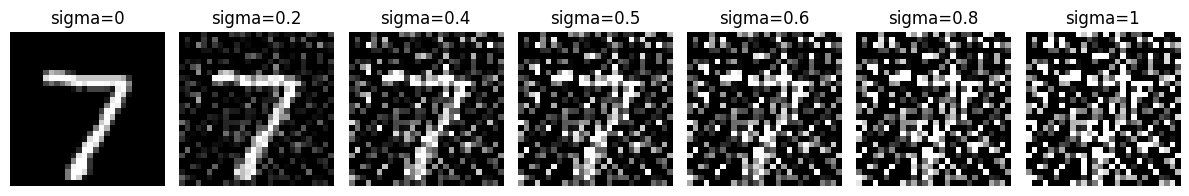

In [ ]:
# The same clean digit and Gaussian draw isolate the effect of sigma.
example = test_images[0:1]
noise = test_epsilon[0:1]
fig, axes = plt.subplots(1, len(SIGMAS), figsize=(12, 2))
for ax, sigma in zip(axes, SIGMAS):
    ax.imshow((example+sigma*noise)[0,0].cpu(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'sigma={sigma:g}'); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT/'1_2_noising.png', dpi=150); plt.show(); plt.close(fig)


## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [ ]:
batch_size = 256
learning_rate = 1e-4
noise_level = .5
hidden_dim = 128
num_epochs = 5


In [ ]:
train_loader = make_loader(batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
seed_everything()
model = UnconditionalUNet(1, hidden_dim).to(device) if GROUP in ('all','denoise') else None
criterion = nn.MSELoss()
# train_epochs creates a fresh Adam optimizer for each independent experiment.


Recorded epoch summaries from the completed GPU run:
{'epoch': 1, 'mse': 0.020797887896498043, 'lr': 0.0001, 'seconds': 42.970815658569336}
{'epoch': 2, 'mse': 0.010746511739989122, 'lr': 0.0001, 'seconds': 35.6583514213562}
{'epoch': 3, 'mse': 0.00929217550555865, 'lr': 0.0001, 'seconds': 37.98409914970398}
{'epoch': 4, 'mse': 0.008672666017214458, 'lr': 0.0001, 'seconds': 40.303401708602905}
{'epoch': 5, 'mse': 0.008301821293433508, 'lr': 0.0001, 'seconds': 45.414610862731934}


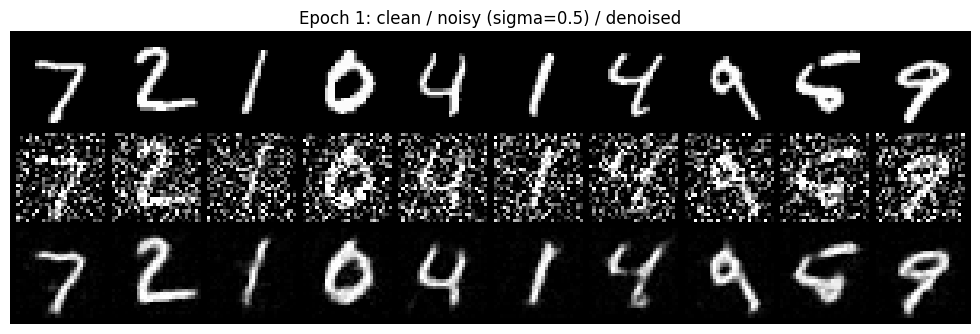

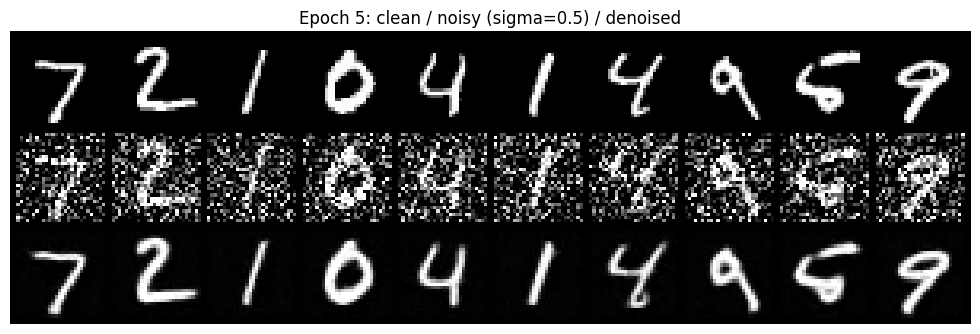

In [ ]:
if GROUP in ('all','denoise'):
    def denoise_objective(net, x, labels):
        noisy = x + noise_level*torch.randn_like(x)
        return F.mse_loss(net(noisy).float(), x.float())
    train_losses = train_epochs(model, 'denoise', train_loader, num_epochs, learning_rate,
                               denoise_objective, denoising_panel)


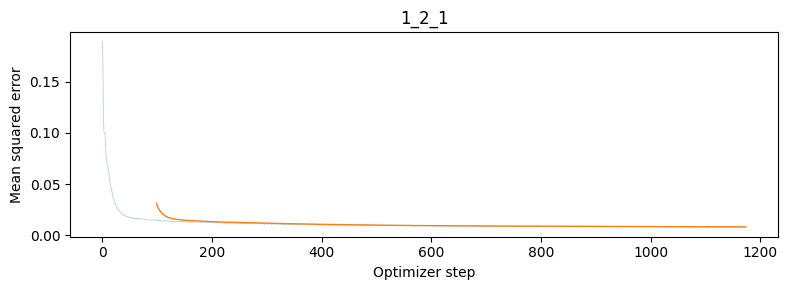

In [ ]:
if GROUP in ('all','denoise'):
    loss_plot(train_losses, '1_2_1')


## Part 1.2.2: Out-of-Distribution Testing

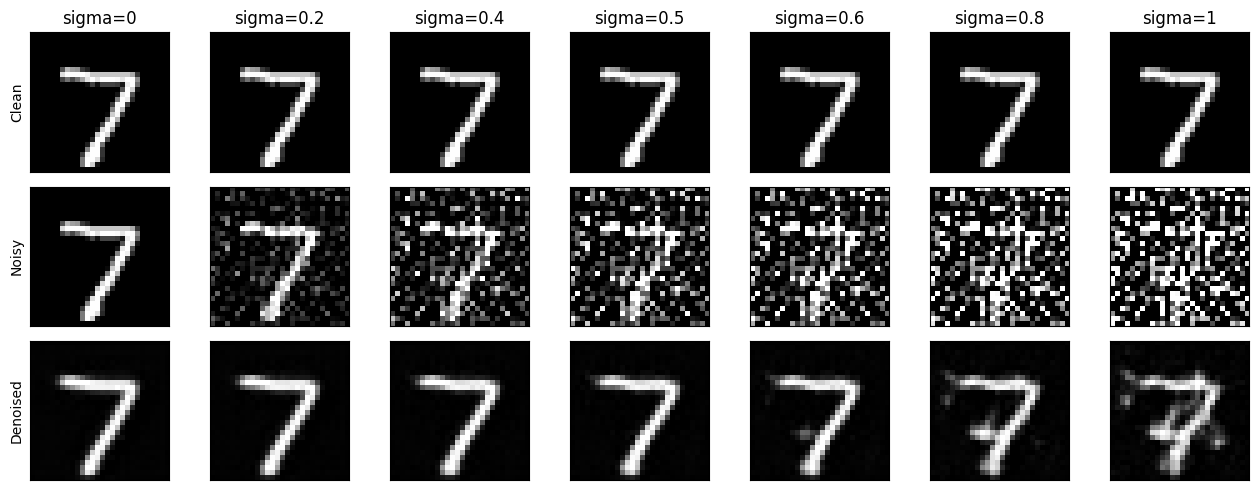

In [ ]:
if GROUP in ('all','denoise'):
    model.eval()
    fig, axes = plt.subplots(3, len(SIGMAS), figsize=(13, 5))
    ood_mse = {}
    with torch.inference_mode():
        for j, sigma in enumerate(SIGMAS):
            noisy = test_images + sigma*test_epsilon
            denoised = model(noisy)
            ood_mse[str(sigma)] = F.mse_loss(denoised, test_images).item()
            for row, image in enumerate((test_images[0,0], noisy[0,0], denoised[0,0])):
                axes[row,j].imshow(image.cpu(), cmap='gray', vmin=0, vmax=1)
                axes[row,j].set_xticks([]); axes[row,j].set_yticks([])
            axes[0,j].set_title(f'sigma={sigma:g}')
    for ax, label in zip(axes[:,0], ['Clean','Noisy','Denoised']): ax.set_ylabel(label)
    fig.tight_layout(); fig.savefig(OUT/'1_2_2_ood.png', dpi=150); plt.show(); plt.close(fig)
    metrics['ood_mse_first10'] = ood_mse; save_metrics()
    del model; release_gpu()


## Part 1.2.3 Denoising Pure Noise

Recorded epoch summaries from the completed GPU run:
{'epoch': 1, 'mse': 0.07361586346626282, 'lr': 0.0001, 'seconds': 43.59245753288269}
{'epoch': 2, 'mse': 0.06756133788029353, 'lr': 0.0001, 'seconds': 44.94702172279358}
{'epoch': 3, 'mse': 0.06744874092737833, 'lr': 0.0001, 'seconds': 44.27045679092407}
{'epoch': 4, 'mse': 0.06741531613270442, 'lr': 0.0001, 'seconds': 44.69627594947815}
{'epoch': 5, 'mse': 0.0674037205417951, 'lr': 0.0001, 'seconds': 43.998754262924194}


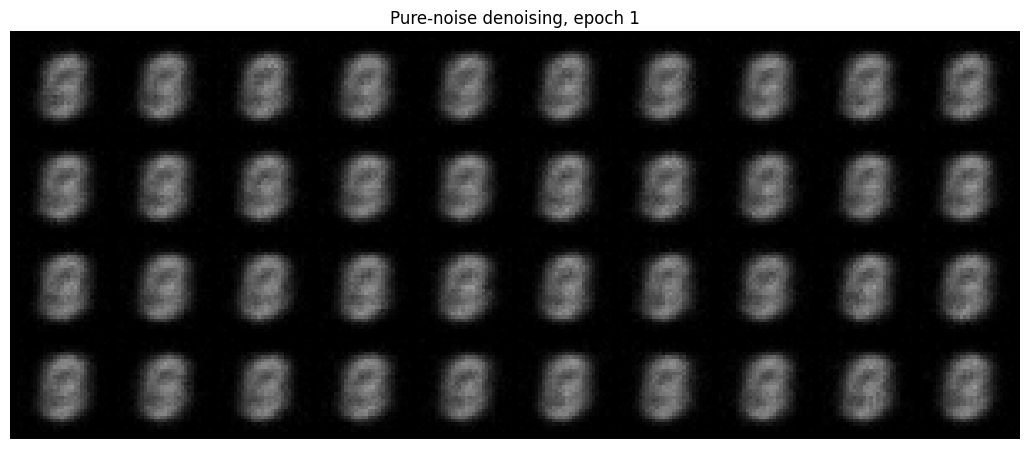

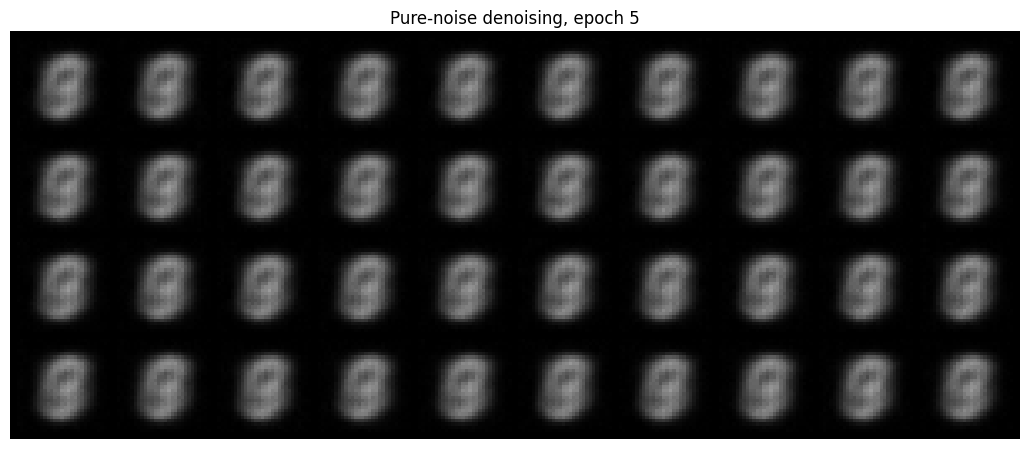

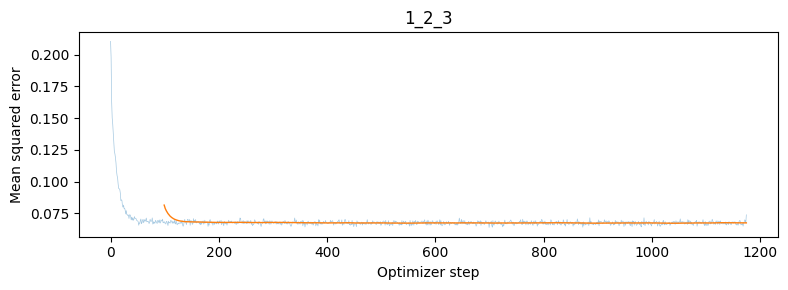

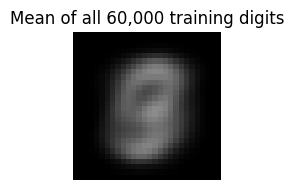

In [ ]:
if GROUP in ('all','denoise'):
    seed_everything()
    pure_model = UnconditionalUNet(1, 128).to(device)
    pure_generator = torch.Generator(device=device).manual_seed(SEED+2)
    pure_test_noise = torch.randn((40,1,28,28), generator=pure_generator, device=device)
    @torch.inference_mode()
    def pure_panel(net, epoch):
        net.eval()
        show_grid(net(pure_test_noise), f'Pure-noise denoising, epoch {epoch}', f'1_2_3_epoch{epoch}.png')
    def pure_objective(net, x, labels):
        return F.mse_loss(net(torch.randn_like(x)).float(), x.float())
    pure_losses = train_epochs(pure_model, 'pure_noise', make_loader(256), 5, 1e-4,
                               pure_objective, pure_panel)
    loss_plot(pure_losses, '1_2_3')
    mean_digit = train_dataset.data.float().mean(0)[None,None]/255
    show_grid(mean_digit, 'Mean of all 60,000 training digits', '1_2_3_training_mean.png', nrow=1)
    # With no information about the target in the input, E[x | noise] = E[x].
    # MSE therefore favors the average digit rather than distinct samples.
    del pure_model; release_gpu()


# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [ ]:
class FCBlock(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__(nn.Linear(in_channels, out_channels), nn.GELU(),
                         nn.Linear(out_channels, out_channels))

class TimeConditionalUNet(UnconditionalUNet):
    def __init__(self, in_channels: int, num_classes: int, num_hiddens: int):
        super().__init__(in_channels, num_hiddens)
        self.fc1_t = FCBlock(1, 2*num_hiddens)
        self.fc2_t = FCBlock(1, num_hiddens)

    def forward(self, x, t):
        h0, h1, h2, u = self.encode(x)
        t = t.reshape(-1, 1).to(dtype=x.dtype)
        u = u * self.fc1_t(t)[:,:,None,None]
        u = self.up1(torch.cat((h2, u), dim=1))
        u = u * self.fc2_t(t)[:,:,None,None]
        u = self.up2(torch.cat((h1, u), dim=1))
        return self.out(torch.cat((h0, u), dim=1))


## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [ ]:
def time_fm_forward(unet, x_1, num_ts):
    # Continuous time, normalized to [0,1]; num_ts controls the sampler only.
    unet.train()
    x_0 = torch.randn_like(x_1)
    t = torch.rand(x_1.shape[0], device=x_1.device)
    xt = (1-t[:,None,None,None])*x_0 + t[:,None,None,None]*x_1
    velocity = unet(xt, t)
    return F.mse_loss(velocity.float(), (x_1-x_0).float())


In [ ]:
@torch.inference_mode()
def time_fm_sample(unet, img_wh, num_ts, seed=0):
    unet.eval()
    dev = next(unet.parameters()).device
    generator = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn((40,1,*img_wh), generator=generator, device=dev)
    for k in range(num_ts):
        t = torch.full((len(x),), k/num_ts, device=dev)
        with amp_context(): velocity = unet(x, t)
        x = x + velocity.float()/num_ts
    return x


In [ ]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

Recorded epoch summaries from the completed GPU run:
{'epoch': 1, 'mse': 0.16887635357379913, 'lr': 0.01, 'seconds': 22.606982707977295}
{'epoch': 2, 'mse': 0.11761488737265269, 'lr': 0.007943282347242816, 'seconds': 19.284345388412476}
{'epoch': 3, 'mse': 0.10653687349557876, 'lr': 0.006309573444801933, 'seconds': 19.28254795074463}
{'epoch': 4, 'mse': 0.10070916585127512, 'lr': 0.005011872336272723, 'seconds': 19.297678232192993}
{'epoch': 5, 'mse': 0.09836983730792999, 'lr': 0.0039810717055349725, 'seconds': 19.345062971115112}
{'epoch': 6, 'mse': 0.09581778660615285, 'lr': 0.0031622776601683794, 'seconds': 19.621817111968994}
{'epoch': 7, 'mse': 0.09397964324156444, 'lr': 0.0025118864315095803, 'seconds': 19.37793207168579}
{'epoch': 8, 'mse': 0.09238138757944107, 'lr': 0.00199526231496888, 'seconds': 19.30968141555786}
{'epoch': 9, 'mse': 0.09166627030769985, 'lr': 0.0015848931924611136, 'seconds': 19.288448810577393}
{'epoch': 10, 'mse': 0.09061659644047419, 'lr': 0.0012589254117

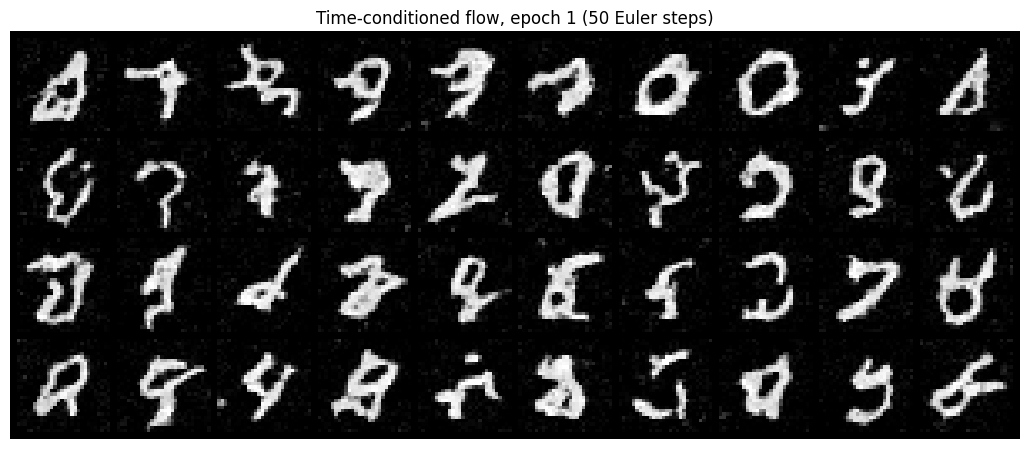

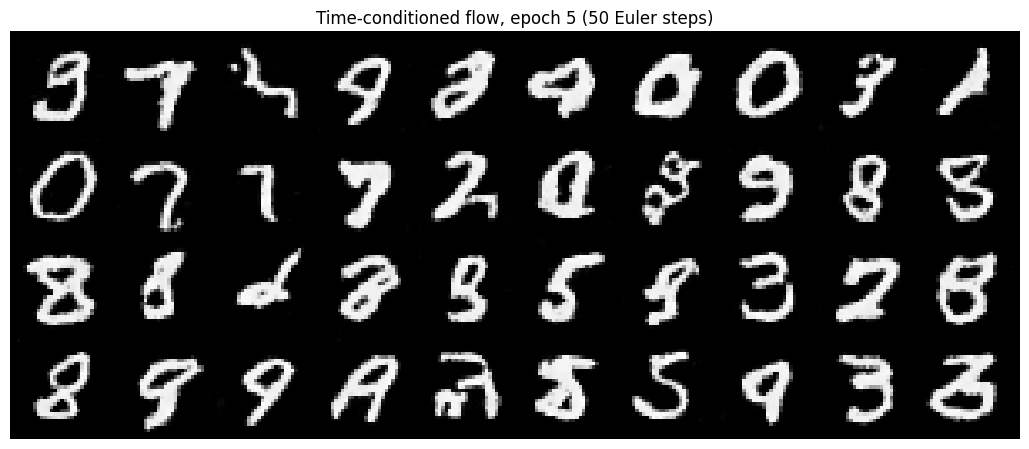

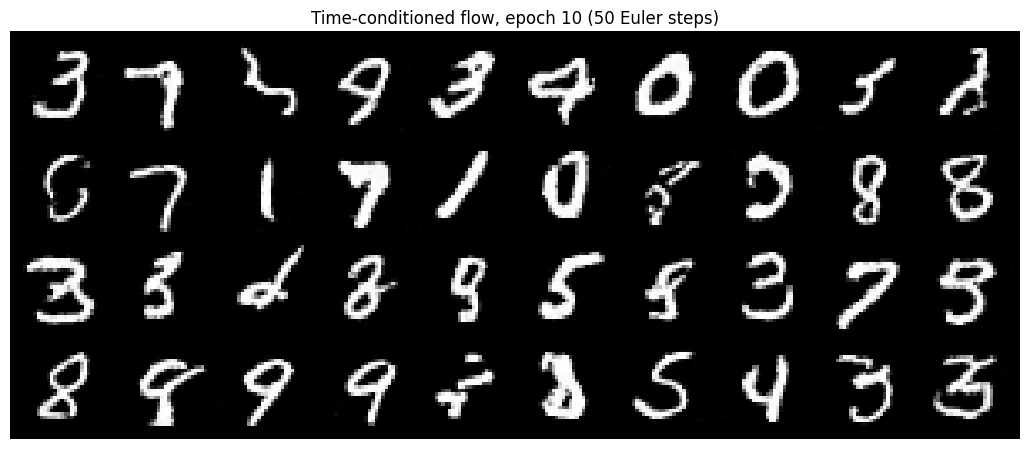

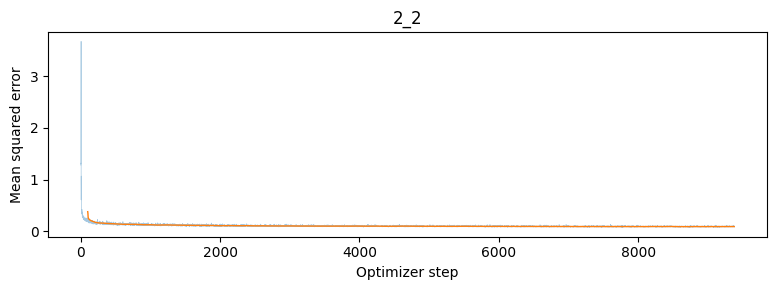

In [ ]:
if GROUP in ('all','time'):
    seed_everything()
    time_unet = TimeConditionalUNet(1, 10, 64).to(device)
    with torch.no_grad():
        assert time_unet(torch.randn(2,1,28,28, device=device), torch.tensor([0.,1.],device=device)).shape == (2,1,28,28)
    @torch.inference_mode()
    def time_panel(net, epoch):
        images = time_fm_sample(net, (28,28), 50, SEED+3)
        show_grid(images, f'Time-conditioned flow, epoch {epoch} (50 Euler steps)', f'2_3_epoch{epoch}.png')
    time_losses = train_epochs(time_unet, 'time_flow', make_loader(64), 10, 1e-2,
                              lambda net,x,c: time_fm_forward(net,x,50), time_panel, decay=True)
    loss_plot(time_losses, '2_2')


# Part 2.3: Sampling from the Time-conditioned UNet

In [ ]:
# Fixed-seed epoch 1, 5, and 10 samples were saved by the training callback.
if GROUP in ('all','time'):
    print('Time-flow samples:', [str(OUT/f'2_3_epoch{e}.png') for e in (1,5,10)])
    del time_unet; release_gpu()


# Part 2.4: Implementing a Class-conditioned UNet

In [ ]:
class ClassConditionalUNet(UnconditionalUNet):
    def __init__(self, in_channels: int, num_classes: int, num_hiddens: int):
        super().__init__(in_channels, num_hiddens)
        self.num_classes = num_classes
        self.fc1_t = FCBlock(1, 2*num_hiddens)
        self.fc2_t = FCBlock(1, num_hiddens)
        self.fc1_c = FCBlock(num_classes, 2*num_hiddens)
        self.fc2_c = FCBlock(num_classes, num_hiddens)

    def forward(self, x, c, t, mask=None):
        h0, h1, h2, u = self.encode(x)
        t = t.reshape(-1,1).to(dtype=x.dtype)
        onehot = F.one_hot(c.long(), self.num_classes).to(dtype=x.dtype)
        if mask is not None: onehot = onehot * mask.reshape(-1,1)
        u = self.fc1_c(onehot)[:,:,None,None]*u + self.fc1_t(t)[:,:,None,None]
        u = self.up1(torch.cat((h2, u), dim=1))
        u = self.fc2_c(onehot)[:,:,None,None]*u + self.fc2_t(t)[:,:,None,None]
        u = self.up2(torch.cat((h1, u), dim=1))
        return self.out(torch.cat((h0, u), dim=1))


In [ ]:
def class_fm_forward(unet, x_1, c, p_uncond, num_ts):
    unet.train()
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), device=x_1.device)
    xt = (1-t[:,None,None,None])*x_0 + t[:,None,None,None]*x_1
    keep = (torch.rand(len(x_1), device=x_1.device) >= p_uncond).to(x_1.dtype)
    prediction = unet(xt, c, t, keep)
    return F.mse_loss(prediction.float(), (x_1-x_0).float())


In [ ]:
@torch.inference_mode()
def class_fm_sample(unet, c, img_wh, num_ts, guidance_scale=5.0, seed=0):
    unet.eval()
    dev = next(unet.parameters()).device
    c = c.to(dev)
    generator = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn((len(c),1,*img_wh), generator=generator, device=dev)
    cache = [x.detach().cpu()]
    # Evaluate conditional and unconditional branches in one batch.
    conditions = torch.cat((c,c))
    masks = torch.cat((torch.zeros(len(c),device=dev), torch.ones(len(c),device=dev)))
    for k in range(num_ts):
        t = torch.full((2*len(c),), k/num_ts, device=dev)
        with amp_context():
            vu, vc = unet(torch.cat((x,x)), conditions, t, masks).chunk(2)
        velocity = vu.float() + guidance_scale*(vc.float()-vu.float())
        x = x + velocity/num_ts
        if (k+1) % max(1,num_ts//20) == 0 or k+1 == num_ts: cache.append(x.detach().cpu())
    return x, torch.stack(cache, dim=1)


In [ ]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

Recorded epoch summaries from the completed GPU run:
{'epoch': 1, 'mse': 0.1655520737171173, 'lr': 0.01, 'seconds': 24.795112133026123}
{'epoch': 2, 'mse': 0.11206811354160309, 'lr': 0.007943282347242816, 'seconds': 19.3819580078125}
{'epoch': 3, 'mse': 0.10140093943675359, 'lr': 0.006309573444801933, 'seconds': 19.579976081848145}
{'epoch': 4, 'mse': 0.09558230937719345, 'lr': 0.005011872336272723, 'seconds': 19.959508895874023}
{'epoch': 5, 'mse': 0.0923628226796786, 'lr': 0.0039810717055349725, 'seconds': 19.983294010162354}
{'epoch': 6, 'mse': 0.08979690336386363, 'lr': 0.0031622776601683794, 'seconds': 20.810637712478638}
{'epoch': 7, 'mse': 0.08785569138526916, 'lr': 0.0025118864315095803, 'seconds': 19.631551504135132}
{'epoch': 8, 'mse': 0.08673926448822021, 'lr': 0.00199526231496888, 'seconds': 19.463250875473022}
{'epoch': 9, 'mse': 0.08536475173234939, 'lr': 0.0015848931924611136, 'seconds': 19.658289194107056}
{'epoch': 10, 'mse': 0.08472480638027191, 'lr': 0.00125892541179

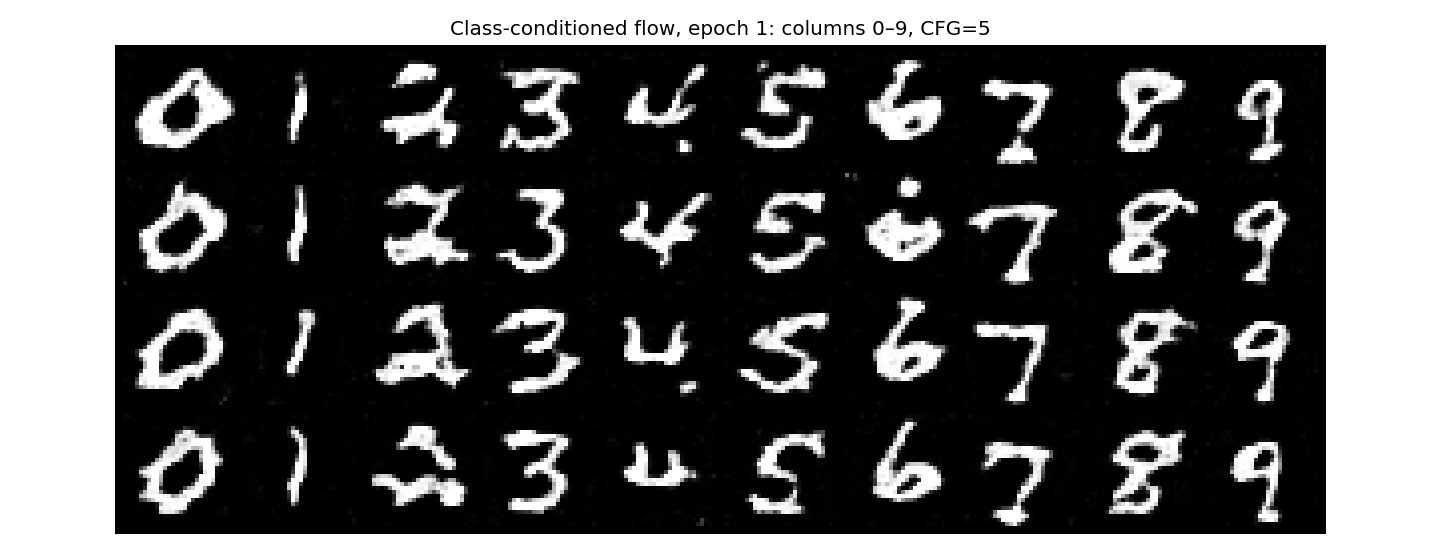

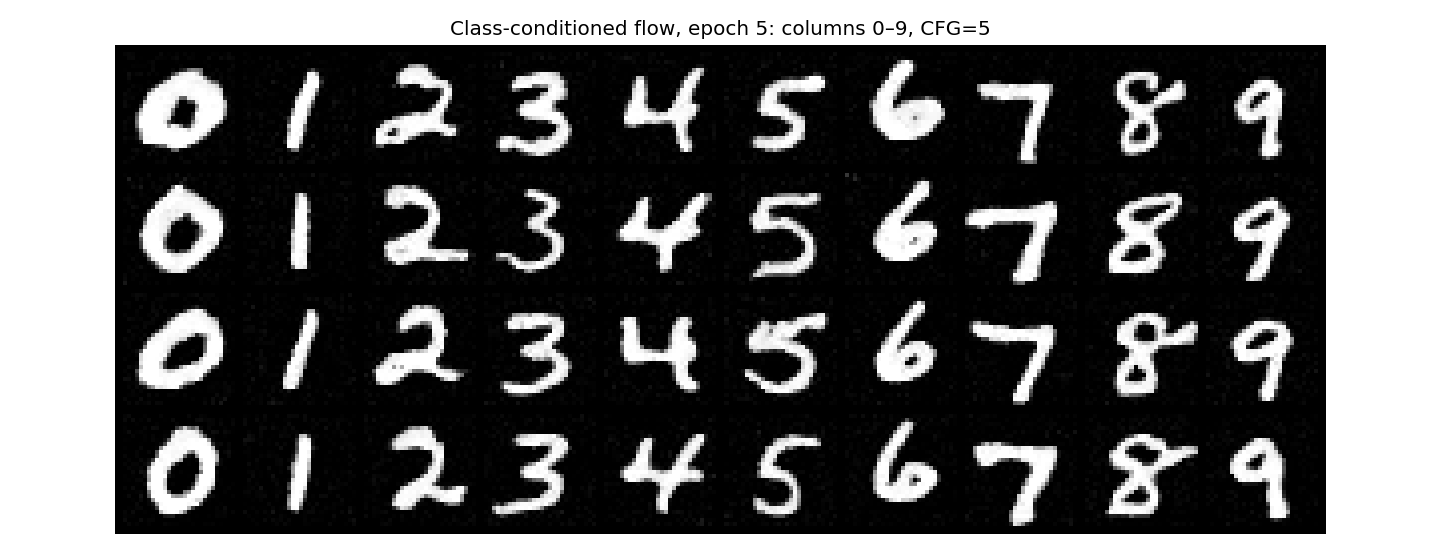

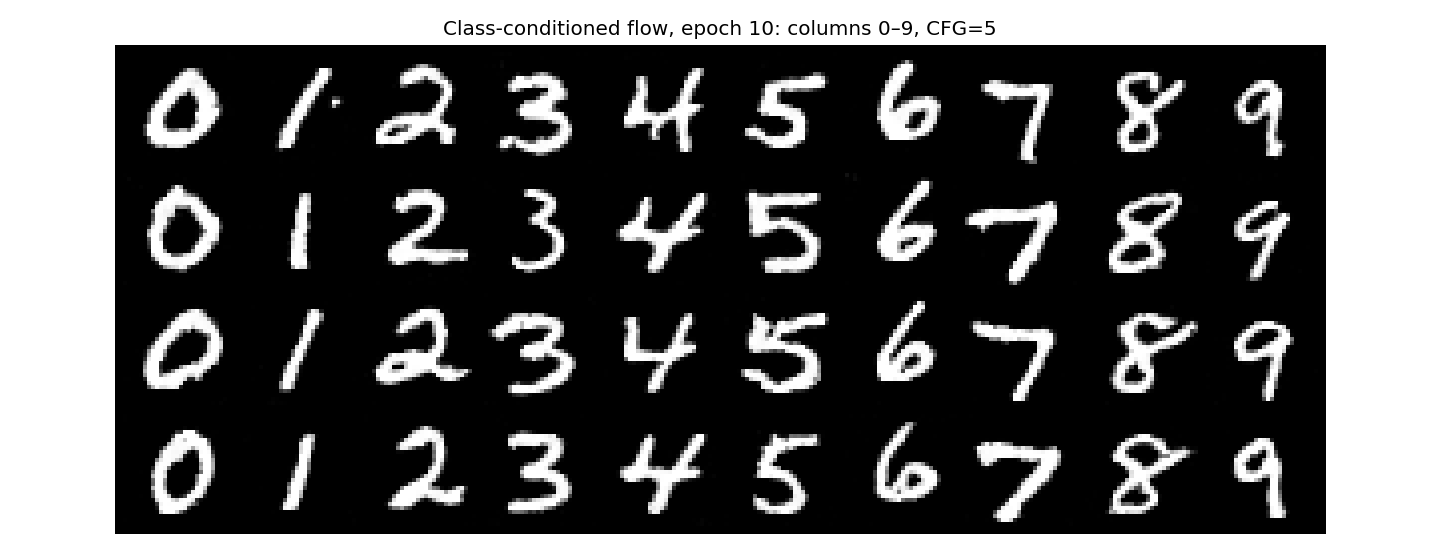

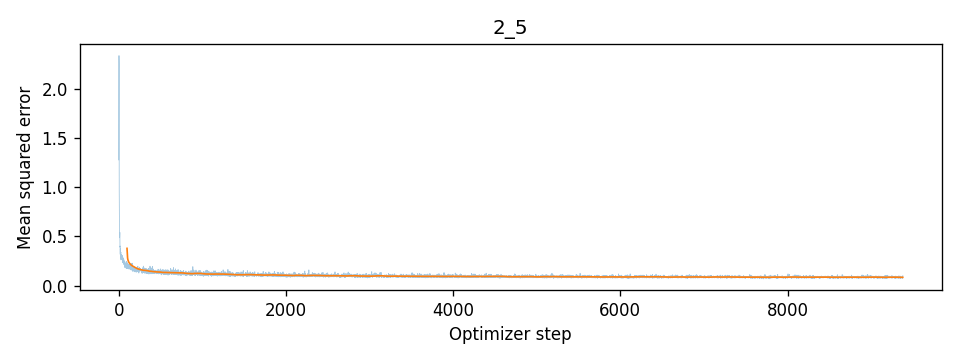

In [ ]:
if GROUP in ('all','class'):
    seed_everything()
    class_unet = ClassConditionalUNet(1,10,64).to(device)
    # Evaluate this invariance check outside batch-normalization training mode.
    class_unet.eval()
    with torch.no_grad():
        _x = torch.randn(2,1,28,28,device=device)
        _c = torch.tensor([2,7],device=device); _t = torch.tensor([.2,.8],device=device)
        assert class_unet(_x,_c,_t).shape == _x.shape
        _zero = torch.zeros(2,device=device)
        _a = class_unet(_x,_c,_t,_zero)
        _b = class_unet(_x,9-_c,_t,_zero)
        print('Dropped-class invariance max difference:', (_a-_b).abs().max().item())
        torch.testing.assert_close(_a, _b, rtol=1e-4, atol=1e-5)
    del _x, _c, _t, _zero, _a, _b
    seed_everything()
    def class_panel(net, epoch, filename=None):
        labels = torch.arange(10, device=device).repeat(4)
        samples, cache = class_fm_sample(net, labels, (28,28), 300, 5., SEED+4)
        show_grid(samples, f'Class-conditioned flow, epoch {epoch}: columns 0–9, CFG=5',
                  filename or f'2_6_epoch{epoch}.png')
        return samples
    class_losses = train_epochs(class_unet, 'class_flow', make_loader(64), 10, 1e-2,
        lambda net,x,c: class_fm_forward(net,x,c,.1,300), class_panel, decay=True)
    loss_plot(class_losses, '2_5')
    del class_unet; release_gpu()


# Part 2.6: Sampling from the Class-conditioned UNet

Recorded epoch summaries from the completed GPU run:
{'epoch': 1, 'mse': 0.1482124322493871, 'lr': 0.003, 'seconds': 19.538915634155273}
{'epoch': 2, 'mse': 0.1097369837363561, 'lr': 0.003, 'seconds': 19.555895805358887}
{'epoch': 3, 'mse': 0.10271131403446197, 'lr': 0.003, 'seconds': 19.5500431060791}
{'epoch': 4, 'mse': 0.09796768697897593, 'lr': 0.003, 'seconds': 19.569565296173096}
{'epoch': 5, 'mse': 0.09465456134080887, 'lr': 0.003, 'seconds': 19.787434577941895}
{'epoch': 6, 'mse': 0.09210025113026302, 'lr': 0.003, 'seconds': 19.658275842666626}
{'epoch': 7, 'mse': 0.0898801926334699, 'lr': 0.003, 'seconds': 19.810115814208984}
{'epoch': 8, 'mse': 0.08873254317442576, 'lr': 0.003, 'seconds': 19.70612931251526}
{'epoch': 9, 'mse': 0.08718531086444854, 'lr': 0.003, 'seconds': 19.872772216796875}
{'epoch': 10, 'mse': 0.08643282097975413, 'lr': 0.003, 'seconds': 19.591938495635986}


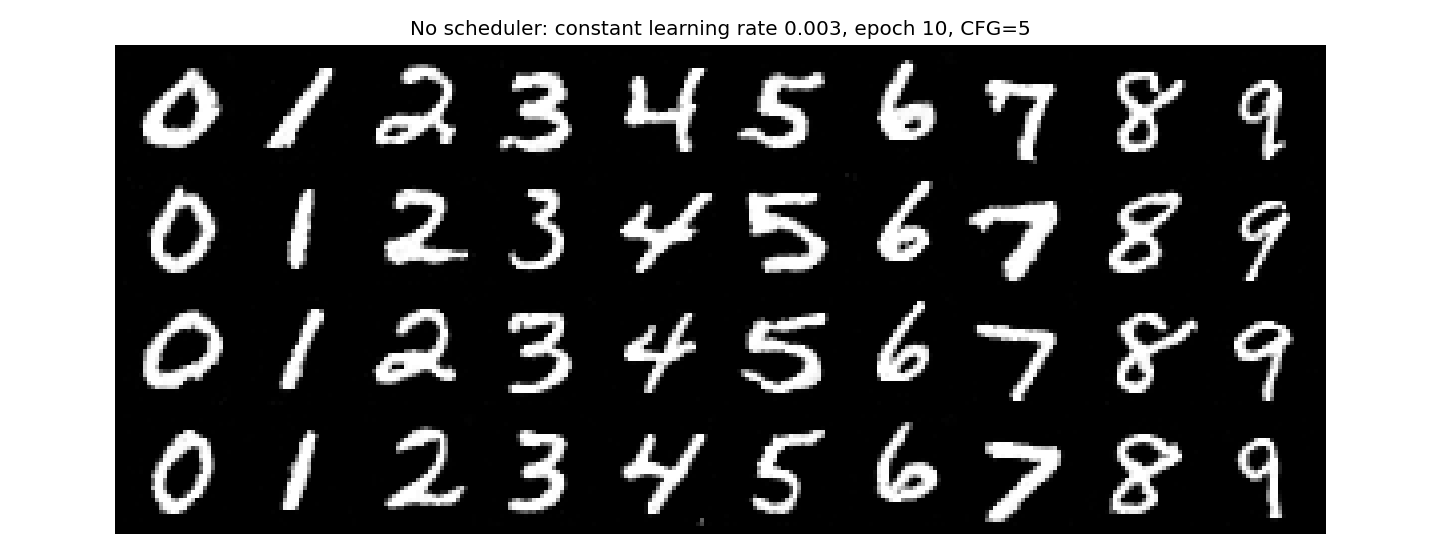

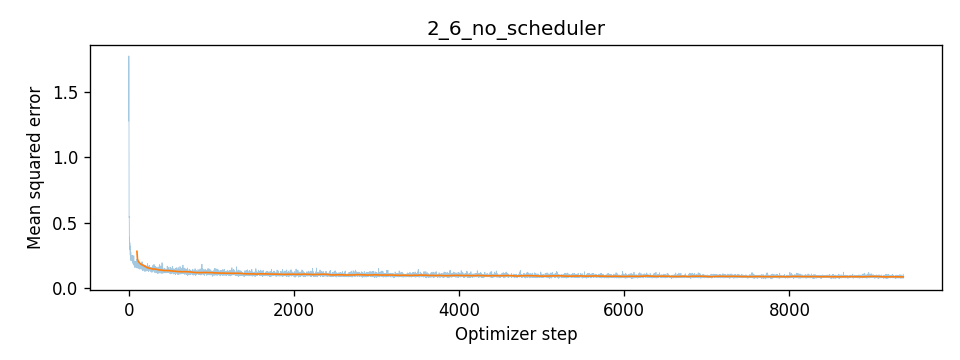

In [ ]:
# Independent comparison: same architecture, seed, data order, 10 epochs,
# dropout and sampler. Constant 0.003 is close to the geometric mean of the
# decaying 0.01-to-0.001 schedule; it avoids taking large updates late in training.
if GROUP in ('all','no_scheduler'):
    seed_everything()
    constant_unet = ClassConditionalUNet(1,10,64).to(device)
    def constant_panel(net, epoch):
        if epoch == 10:
            labels = torch.arange(10,device=device).repeat(4)
            samples, _ = class_fm_sample(net, labels, (28,28), 300, 5., SEED+4)
            show_grid(samples, 'No scheduler: constant learning rate 0.003, epoch 10, CFG=5',
                      '2_6_no_scheduler.png')
    constant_losses = train_epochs(constant_unet, 'class_constant_lr', make_loader(64), 10, .003,
        lambda net,x,c: class_fm_forward(net,x,c,.1,300), constant_panel)
    loss_plot(constant_losses, '2_6_no_scheduler')
    del constant_unet; release_gpu()
print('All selected experiments completed. Export results in the final cell.')


## Export results and checkpoints
Download both archives before disconnecting. The first contains website figures and raw measurements; the second preserves learned weights.


In [ ]:
save_metrics()
required = ['1_2_noising.png','1_2_1_epoch1.png','1_2_1_epoch5.png','1_2_1_loss.png',
 '1_2_2_ood.png','1_2_3_epoch1.png','1_2_3_epoch5.png','1_2_3_loss.png',
 '2_2_loss.png','2_3_epoch1.png','2_3_epoch5.png','2_3_epoch10.png',
 '2_5_loss.png','2_6_epoch1.png','2_6_epoch5.png','2_6_epoch10.png','2_6_no_scheduler.png']
missing = [name for name in required if not (OUT/name).exists()]
if GROUP == 'all': assert not missing, f'Missing deliverables: {missing}'
archive = shutil.make_archive('partb_results', 'zip', root_dir='results')
weights = shutil.make_archive('partb_checkpoints', 'zip', root_dir=CKPT)
print('COMPLETE:', len(list(OUT.glob('*.png'))), 'figures;', archive, weights)
if IN_COLAB:
    from google.colab import files
    files.download(archive)
    files.download(weights)
